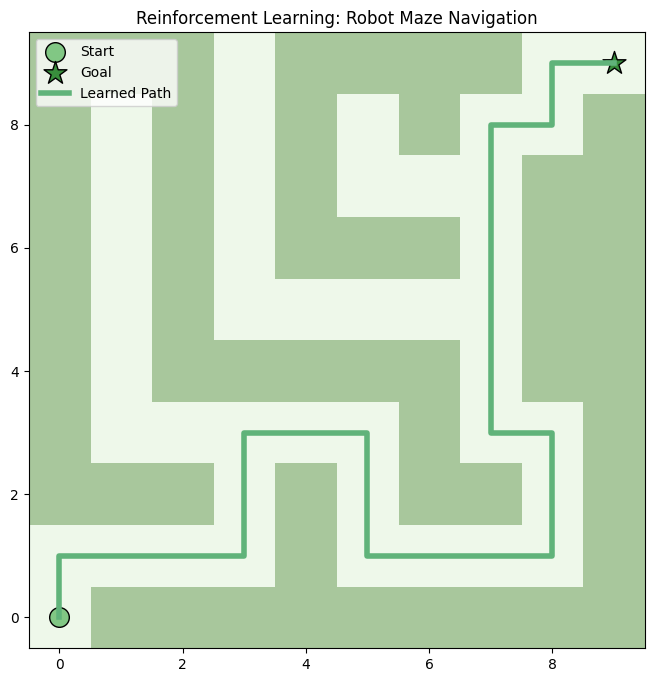

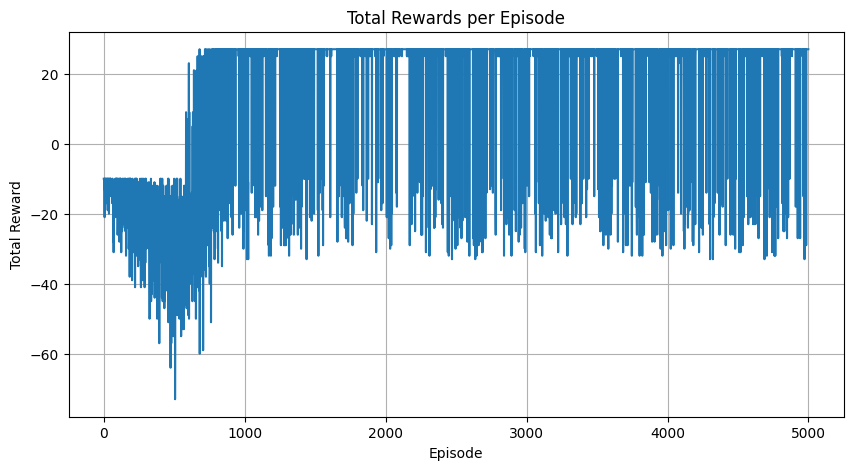

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Step 1: Definisikan Maze, Start, dan Goal
maze = np.array([
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 0, 1, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 1, 1],
    [1, 0, 1, 0, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 0, 1],
    [1, 1, 1, 0, 1, 1, 1, 1, 0, 0]
])

start = (0, 0)
goal = (9, 9)

# Step 2: Parameter RL dan Inisialisasi Q-Table
num_episodes = 5000
alpha = 0.1
gamma = 0.9
epsilon = 0.5

reward_fire = -10
reward_goal = 50
reward_step = -1

actions = [(0, -1), (0, 1), (-1, 0), (1, 0)]
Q = np.zeros(maze.shape + (len(actions),))

def is_valid(pos):
    r, c = pos
    return 0 <= r < maze.shape[0] and 0 <= c < maze.shape[1] and maze[r, c] == 0

def choose_action(state):
    if np.random.random() < epsilon:
        return np.random.randint(len(actions))
    else:
        return np.argmax(Q[state])

# Step 3: Training Agent dengan Q-Learning
rewards_all_episodes = []

for episode in range(num_episodes):
    state = start
    total_rewards = 0
    done = False

    while not done:
        action_index = choose_action(state)
        action = actions[action_index]
        next_state = (state[0] + action[0], state[1] + action[1])

        if not is_valid(next_state):
            reward = reward_fire
            done = True
        elif next_state == goal:
            reward = reward_goal
            done = True
        else:
            reward = reward_step

        old_value = Q[state][action_index]
        next_max = np.max(Q[next_state]) if is_valid(next_state) else 0
        Q[state][action_index] = old_value + alpha * (reward + gamma * next_max - old_value)

        state = next_state
        total_rewards += reward

    epsilon = max(0.01, epsilon * 0.995)
    rewards_all_episodes.append(total_rewards)

# Step 4: Visualisasi Jalur Optimal
def get_optimal_path(Q, start, goal, actions, maze, max_steps=200):
    path = [start]
    state = start
    visited = set()

    for _ in range(max_steps):
        if state == goal:
            break
        visited.add(state)
        best_action = np.argmax(Q[state])
        move = actions[best_action]
        next_state = (state[0] + move[0], state[1] + move[1])
        if not is_valid(next_state) or next_state in visited:
            break
        state = next_state
        path.append(state)
    return path

optimal_path = get_optimal_path(Q, start, goal, actions, maze)

def plot_maze_with_path(path):
    cmap = ListedColormap(['#eef8ea', '#a8c79c'])
    plt.figure(figsize=(8, 8))
    plt.imshow(maze, cmap=cmap)
    plt.scatter(start[1], start[0], marker='o', color='#81c784', edgecolors='black', s=200, label='Start')
    plt.scatter(goal[1], goal[0], marker='*', color='#388e3c', edgecolors='black', s=300, label='Goal')
    rows, cols = zip(*path)
    plt.plot(cols, rows, color='#60b37a', linewidth=4, label='Learned Path')
    plt.gca().invert_yaxis()
    plt.legend()
    plt.title("Reinforcement Learning: Robot Maze Navigation")
    plt.show()

plot_maze_with_path(optimal_path)

def plot_rewards(rewards):
    plt.figure(figsize=(10, 5))
    plt.plot(rewards)
    plt.title('Total Rewards per Episode')
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.grid(True)
    plt.show()

plot_rewards(rewards_all_episodes)
